# 🛠️ **IMPORTS**: Bibliotecas

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 💻 **CÓDIGOS**: Implementação

In [2]:
file_mun = "../data/dtb/RELATORIO_DTB_BRASIL_2024_MUNICIPIOS.xlsx"
file_dist = "../data/dtb/RELATORIO_DTB_BRASIL_2024_DISTRITOS.xlsx"
file_subdist = "../data/dtb/RELATORIO_DTB_BRASIL_2024_SUBDISTRITOS.xlsx"

df_mun = pd.read_excel(file_mun)
df_dist = pd.read_excel(file_dist)
df_subdist = pd.read_excel(file_subdist)
print("Arquivos carregados com sucesso.")

Arquivos carregados com sucesso.


In [3]:
#GROUP_BY - NUMERO DE MUNICÍPIOS POR UF
df_mun_por_uf = df_mun.groupby('Nome_UF')['Código Município Completo'].nunique().reset_index()
df_mun_por_uf.columns = ['Nome_UF', 'Total_Municipios']
df_mun_por_uf_sorted = df_mun_por_uf.sort_values(by='Total_Municipios', ascending=False)
print("\n--- Municípios por Estado (Top 5) ---")
print(df_mun_por_uf_sorted.head())


--- Municípios por Estado (Top 5) ---
              Nome_UF  Total_Municipios
12       Minas Gerais               853
25          São Paulo               645
19  Rio Grande do Sul               497
4               Bahia               417
13             Paraná               399


In [4]:
#CONTAR OS DISTRITOS
dist_count = df_dist.groupby('Código Município Completo')['Distrito'].count().reset_index()
dist_count.columns = ['Código Município Completo', 'Total_Distritos']

#CONTAR OS SUBSDISTRITOS
subdist_count = df_subdist.groupby('Código Município Completo')['Subdistrito'].count().reset_index()
subdist_count.columns = ['Código Município Completo', 'Total_Subdistritos']

#JUNTAR TUDO E TOTALIZAR
df_merged = pd.merge(dist_count, subdist_count, on='Código Município Completo', how='outer').fillna(0)
df_merged['Total_Geral'] = df_merged['Total_Distritos'] + df_merged['Total_Subdistritos']

#ASSOCIAR ID AO NOME
df_mun_nomes = df_mun[['Código Município Completo', 'Nome_Município', 'Nome_UF']].drop_duplicates()
df_top_distritos = pd.merge(df_merged, df_mun_nomes, on='Código Município Completo', how='left')

#TOP 10
df_top_10 = df_top_distritos.sort_values(by='Total_Geral', ascending=False).head(10)
print("\n--- Top 10 Municípios por Distritos e Subdistritos ---")
print(df_top_10[['Nome_Município', 'Nome_UF', 'Total_Distritos', 'Total_Subdistritos', 'Total_Geral']])

#SALVANDO
df_top_10.to_csv('../data/dtb/df_top_10_distritos.csv', index=False)

df_top_10['Rotulo'] = df_top_10['Nome_Município'] + '(' +df_top_10['Nome_UF'] + ')'


--- Top 10 Municípios por Distritos e Subdistritos ---
      Nome_Município            Nome_UF  Total_Distritos  Total_Subdistritos  \
3829       São Paulo          São Paulo               96                 0.0   
5418         Goiânia              Goiás                2                63.0   
4120         Maringá             Paraná                3                47.0   
4949      Rio Grande  Rio Grande do Sul                5                42.0   
5570        Brasília   Distrito Federal                1                35.0   
3242  Rio de Janeiro     Rio de Janeiro                1                33.0   
4979    Santo Ângelo  Rio Grande do Sul               15                18.0   
2448        Contagem       Minas Gerais                2                30.0   
4910     Passo Fundo  Rio Grande do Sul                7                22.0   
3182     Barra Mansa     Rio de Janeiro                6                19.0   

      Total_Geral  
3829         96.0  
5418         65.0  
412

# 📊 Gráfico 1: Total de Municípios por Estado (UF)

**Este gráfico de barras** apresenta a distribuição do número de municípios em cada Unidade da Federação.

---

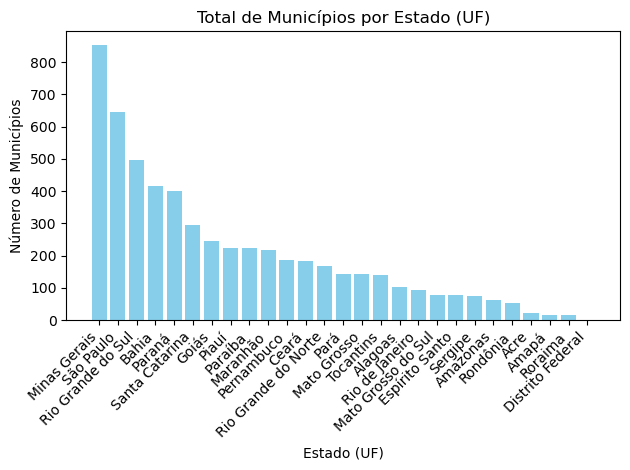

In [5]:
plt.figure(1)
plt.clf()
plt.bar(df_mun_por_uf_sorted['Nome_UF'], df_mun_por_uf_sorted['Total_Municipios'], color='skyblue')
plt.xticks(rotation=45, ha='right')
plt.title('Total de Municípios por Estado (UF)')
plt.xlabel('Estado (UF)')
plt.ylabel('Número de Municípios')
plt.tight_layout()
plt.show()

# 🏙️ Gráfico 2: Top 10 Municípios com Mais Distritos e Subdistritos

**Este gráfico de barras** exibe os 10 municípios que possuem o maior número somado de distritos e subdistritos.

---

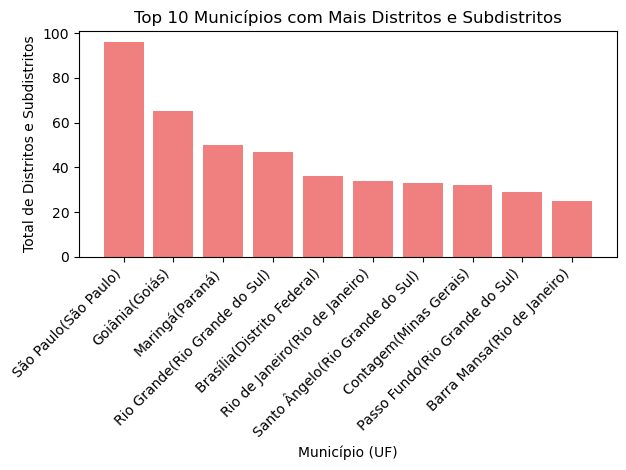

In [6]:
plt.figure(2)
plt.clf()
plt.bar(df_top_10['Rotulo'], df_top_10['Total_Geral'], color='lightcoral')
plt.xticks(rotation=45, ha='right')
plt.title('Top 10 Municípios com Mais Distritos e Subdistritos')
plt.xlabel('Município (UF)')
plt.ylabel('Total de Distritos e Subdistritos')
plt.tight_layout()
plt.show()